# CS3 - Field-Scale Screening & Well Ranking (Costa carbonate field)

**Petrophys Case Studies - a realistic end-to-end project**

---

## 1. The brief

> *"We have logs and core from all 17 wells in the Costa carbonate field. Before we
> commit capital to a development plan, screen the whole field: rank the wells by
> reservoir quality and remaining hydrocarbon volume, and hand me a short list of the
> best candidates for development - with a defensible rationale."*
> &mdash; Asset manager, subsurface team

This is a **portfolio / screening** problem, not a single-well study. The deliverable is
a **ranked field screening table (17 rows)**, a **cross-well comparison figure set**, and a
**"top candidates for development" recommendation**.

Two things make field screening different from single-well work:

1. **Consistency matters more than depth-by-depth precision.** If we interpret each well
   with a slightly different recipe, the ranking is meaningless. We fix one workflow and
   apply it identically to all 17 wells.
2. **Logs must be made comparable across wells.** Gamma-ray in particular drifts between
   wells (different tool calibration, hole conditions, mud). Before we compare clay content
   well-to-well we **normalize GR** to a common scale. We show the before/after.

We build on two earlier case studies and *reuse* their verified recipes rather than
re-teach them:

- **CS1** (clastic full formation evaluation) - the general FE chain.
- **CS2** (Costa carbonate rock typing) - the exact carbonate recipe for a *single* Costa
  well: limestone-matrix porosity, header Archie parameters, and the critical
  **Rw temperature correction**. CS3 turns that single-well recipe into a batch loop.


### The one correctness step that dominates the whole field: Rw at formation temperature

The Costa LAS headers quote water resistivity `RW` at a reference temperature
`RWT` (~68 degF, i.e. lab/surface). Formation temperature is far higher
(`BHT` ~ 251 degF). Resistivity of brine *falls* as temperature rises, so using the
quoted `RW` directly makes the formation look far more resistive than it is and drives
**Archie Sw to or above 1.0** almost everywhere (only the very best rock stays just below).

We correct `RW` from `RWT` to the formation temperature *at each depth* using the Arps
relation before running Archie:

$$ R_w(T_f) = R_w(T_{ref}) \cdot \frac{T_{ref} + 6.77}{T_f + 6.77} \quad (\text{degF}) $$

Get this wrong once and every well in the ranking is wrong. This is the single most
important line in the batch loop.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import petrophys
from petrophys.io import read_las

# Physics modules - all verified against source in CS1/CS2
from petrophys.interpretation import porosity as poro
from petrophys.interpretation import saturation as sat
from petrophys.interpretation.temperature import calculate_temperature_profile, arps_equation
import petrophys.evaluation as res_mod
from petrophys.preprocessing.normalization import normalize_log

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)

WELLS = petrophys.list_samples('costa')
print('petrophys', petrophys.__version__)
print('Costa field: %d wells' % len(WELLS))
print(WELLS)

petrophys 3.0.0
Costa field: 17 wells
['HW-10', 'HW-24', 'HW-25', 'HW-26', 'HW-27', 'HW-28', 'HW-29', 'HW-3', 'HW-30', 'HW-31', 'HW-32', 'HW-4', 'HW-5', 'HW-6', 'HW-7', 'HW-8', 'HW-9']


## 2. The wells & the data

All 17 Costa wells are **carbonate**, logged in **feet**, ~400 samples each (337-481) at
0.5 ft step. Each carries a compact but complete suite:

- **Logs:** `GR`, `RHOB`, `NPHI`, `DT` (sonic), `RT` (deep resistivity).
- **Core:** `PHIE_CC` (core porosity), `PERM_CC` (core permeability), `SW_INPUT` (core Sw).
- **Header Archie parameters** (via `well.get_parameter`): `RW`, `RWT`, `A`, `M`, `N`, `BHT`.

Let's inventory the field so we know exactly what we are working with - including any wells
with missing curves or missing header parameters, because those drive our error handling.


In [2]:
inv = []
for wn in WELLS:
    w = read_las(petrophys.sample(wn))
    row = {'well': w.name, 'samples': w.n_samples,
           'top_ft': round(w.start_depth, 1), 'base_ft': round(w.stop_depth, 1)}
    # curve presence + how much DT is actually populated (some wells have all-null sonic)
    for m in ['GR', 'RHOB', 'NPHI', 'DT', 'RT', 'PHIE_CC', 'PERM_CC', 'SW_INPUT']:
        row[m] = w.get(m).valid_count() if w.has_curve(m) else 0
    # header Archie params
    for p in ['RW', 'RWT', 'A', 'M', 'N', 'BHT']:
        v = w.get_parameter(p)
        row[p] = v
    inv.append(row)

inv_df = pd.DataFrame(inv)
print('CURVE VALID-SAMPLE COUNTS (0 = curve absent / all-null):')
print(inv_df[['well', 'samples', 'GR', 'RHOB', 'NPHI', 'DT', 'RT',
              'PHIE_CC', 'PERM_CC', 'SW_INPUT']].to_string(index=False))

CURVE VALID-SAMPLE COUNTS (0 = curve absent / all-null):
 well  samples  GR  RHOB  NPHI  DT  RT  PHIE_CC  PERM_CC  SW_INPUT
HW-10      381 381   381   381   0 381      381      311       160
HW-24      433 433   433   433   0 433      433      389       352
HW-25      413 413   413   413   0 413      413      334       332
HW-26      345 345   345   345   0 345      309      321       230
HW-27      409 409   409   273 409 409      409      335        13
HW-28      407 407   407   407 407 407      407      333        95
HW-29      445 445   445   445   0 445      445      355       393
 HW-3      431 431   431   431 356 431      351      355       321
HW-30      481 481   481   481 481 481      481      470       445
HW-31      421 421   421   421 421 421      421      413         0
HW-32      419 419   419   419 419 419      419      404       343
 HW-4      361 361   361   361   0 361      361      307       126
 HW-5      337 337   337   337 337 337      337      286        74
 HW-6

In [3]:
print('HEADER ARCHIE PARAMETERS (read live from each LAS):')
print(inv_df[['well', 'RW', 'RWT', 'A', 'M', 'N', 'BHT']].to_string(index=False))
print()
# Flag the data-quality issues that will shape our batch loop
dt_dead = inv_df[inv_df['DT'] == 0]['well'].tolist()
mn_miss = inv_df[inv_df['M'].isna() | inv_df['N'].isna()]['well'].tolist()
print('Wells with dead/absent sonic (DT):', dt_dead if dt_dead else 'none')
print('Wells missing header M and/or N :', mn_miss if mn_miss else 'none')

HEADER ARCHIE PARAMETERS (read live from each LAS):
 well     RW  RWT   A    M    N   BHT
HW-10 0.1373 68.0 1.0 2.03 2.00 251.0
HW-24 0.0760 68.0 1.0 1.97 1.99 251.0
HW-25 0.0778 68.0 1.0 1.97 1.98 251.0
HW-26 0.0702 68.0 1.0 2.01 2.00 251.0
HW-27 0.1000 68.0 1.0  NaN  NaN 251.0
HW-28 0.0760 68.0 1.0 1.95 2.06 251.0
HW-29 0.0847 68.0 1.0 1.94 1.96 251.0
 HW-3 0.0682 68.0 1.0 2.03 2.00 251.0
HW-30 0.0690 68.0 1.0 2.02 2.00 251.0
HW-31 0.1000 68.0 1.0  NaN  NaN 251.0
HW-32 0.0750 68.0 1.0 1.96 1.99 251.0
 HW-4 0.0698 68.0 1.0 2.01 2.03 251.0
 HW-5 0.0850 68.0 1.0 1.91 2.15 251.0
 HW-6 0.0733 68.0 1.0 1.98 2.01 251.0
 HW-7 0.1000 68.0 1.0  NaN  NaN 251.0
 HW-8 0.1000 68.0 1.0  NaN  NaN 251.0
 HW-9 0.1349 68.0 1.0 2.04 1.92 251.0

Wells with dead/absent sonic (DT): ['HW-10', 'HW-24', 'HW-25', 'HW-26', 'HW-29', 'HW-4', 'HW-6', 'HW-7', 'HW-8', 'HW-9']
Wells missing header M and/or N : ['HW-27', 'HW-31', 'HW-7', 'HW-8']


### What the inventory tells us (and how it shapes the loop)

Two data-quality realities emerge, and both must be handled *gracefully* rather than by
crashing or silently dropping a well:

1. **Sonic (`DT`) is unreliable on some wells.** We deliberately build the porosity /
   saturation recipe on **GR / RHOB / NPHI / RT only**, so a dead sonic never breaks a well.
2. **A subset of wells is missing header `M` and `N`** (the Archie cementation and
   saturation exponents). We do **not** drop these wells. Instead we fall back to
   **field-typical carbonate defaults `M = N = 2.0`** and *flag* the well as using defaults,
   so the reader can discount its Sw. Dropping wells from a screening study biases the
   portfolio; flagging them is the honest choice.

Everything else (RW/RWT/A/BHT) is present on every well.


## 3. Workflow plan

We chain the following steps and apply them **identically** to every well:

| # | Step | Module | Why here |
|---|------|--------|----------|
| 1 | Load LAS + header params | `read_las`, `get_parameter` | one recipe, real params |
| 2 | Porosity (N-D, limestone) | `porosity.density_porosity`, `total_porosity` | carbonate matrix 2.71 |
| 3 | Temperature profile | `calculate_temperature_profile` | need T_f at each depth |
| 4 | **Rw -> formation T** | `arps_equation` | *the* correctness step |
| 5 | Archie Sw | `saturation.archie` | real header m/n (or flagged default) |
| 6 | Vcl from GR | inline linear | net-pay clay cutoff |
| 7 | Net reservoir / net pay | `reservoir.calculate_net_pay` | carbonate cutoffs |
| 8 | Per-well roll-up | numpy | avg PHIE, avg Sw, **HC-pore-thickness** |

**Cross-well GR normalization** (Part 4b) sits *beside* this loop: we compute it on the raw
GR of all wells to demonstrate comparability, and confirm our clean/clay GR anchors are
sensible field-wide.

### The screening metric: hydrocarbon pore thickness (HCPT)

Net pay in feet alone is a blunt ranking key - a thick but tight/wet interval can out-rank a
thin, clean, oil-charged one. We rank on **hydrocarbon pore thickness**, a per-well HCPV
index that folds in porosity *and* hydrocarbon saturation over the pay:

$$ \text{HCPT} = \sum_{\text{net pay}} \phi_e \,(1 - S_w)\; \Delta z \quad [\text{ft}] $$

It is the (area-independent) core of any HCPV calculation: multiply by drainage area and a
recovery/formation-volume factor to get reserves. For screening, HCPT ranks wells directly
by *how much movable hydrocarbon column each well actually sees*.


## 4. Execution

### 4a. One recipe, applied to all 17 wells

The function below is the CS2 single-well carbonate recipe wrapped for batch use, with two
robustness additions: (i) missing `M`/`N` fall back to `2.0` and set a flag; (ii) the whole
body is guarded so any unexpected failure is *reported*, not fatal. Cutoffs are the standard
carbonate set: `Vcl < 0.30`, `PHIE > 0.10`, `Sw < 0.60`.


In [4]:
RHOB_MATRIX, RHOB_FLUID = 2.71, 1.00   # calcite matrix, fresh filtrate
VCL_CLEAN, VCL_CLAY = 8.0, 40.0        # GR gAPI anchors (clean carbonate / clay)
# Costa project cutoffs: deliberately tighter than the generic carbonate
# standard (STANDARD_CUTOFFS['carbonate'] = vcl 0.30 / phie 0.045 / sw 0.70)
# because the Kharaib is a high-porosity carbonate and this screening
# targets quality rock. Same set across cs2 / cs3 / lesson 18.
COSTA_CUTOFFS = dict(vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)
VCL_CUT, PHIE_CUT, SW_CUT = (COSTA_CUTOFFS["vcl_cutoff"],
                             COSTA_CUTOFFS["phie_cutoff"],
                             COSTA_CUTOFFS["sw_cutoff"])
DEFAULT_M, DEFAULT_N = 2.0, 2.0        # carbonate fallback when header lacks m/n


def screen_well(well_name):
    """Full carbonate screening recipe for one Costa well.

    Returns a dict of screening metrics, or a dict with 'error' set on failure.
    Never raises - field screening must survive one bad well.
    """
    try:
        w = read_las(petrophys.sample(well_name))
        step = w.step

        # --- header params (with graceful m/n fallback) ---
        rw  = w.get_parameter('RW')
        rwt = w.get_parameter('RWT')
        a   = w.get_parameter('A')
        m   = w.get_parameter('M')
        n   = w.get_parameter('N')
        bht = w.get_parameter('BHT')
        flags = []
        if m is None:
            m = DEFAULT_M; flags.append('M=def')
        if n is None:
            n = DEFAULT_N; flags.append('N=def')

        # --- (2) porosity: neutron-density, limestone matrix ---
        rhob = w.get('RHOB').data
        nphi = w.get('NPHI').data
        phid = poro.density_porosity(rhob, RHOB_MATRIX, RHOB_FLUID)
        phi  = np.clip(poro.total_porosity(nphi, phid, method='adaptive'), 0.0, 0.45)

        # --- (3-4) temperature profile then Rw -> formation temperature (Arps) ---
        tprof = calculate_temperature_profile(w, bht=bht, surface_temp=rwt)
        tf    = tprof.temperature
        rw_fm = arps_equation(rw, rwt, tf)          # <-- the correctness step

        # --- (5) Archie Sw with formation-temperature Rw ---
        sw = np.clip(sat.archie(w.get('RT').data, rw_fm, phi, a=a, m=m, n=n), 0.0, 1.0)

        # --- (6) Vcl from GR (linear) ---
        gr  = w.get('GR').data
        vcl = np.clip((gr - VCL_CLEAN) / (VCL_CLAY - VCL_CLEAN), 0.0, 1.0)

        # --- (7) net reservoir / net pay (carbonate cutoffs) ---
        w.add_curve('VCL',  vcl)
        w.add_curve('PHIE', phi)
        w.add_curve('SW',   sw)
        npr = res_mod.calculate_net_pay(w, vcl_cutoff=VCL_CUT, phie_cutoff=PHIE_CUT,
                                        sw_cutoff=SW_CUT, lithology='carbonate')
        pay = np.asarray(npr.net_pay, dtype=bool)

        # --- (8) per-well roll-up ---
        if pay.any():
            avg_phie = float(np.nanmean(phi[pay]))
            avg_sw   = float(np.nanmean(sw[pay]))
            hcpt     = float(np.nansum(phi[pay] * (1.0 - sw[pay])) * step)   # ft
        else:
            avg_phie = np.nan; avg_sw = np.nan; hcpt = 0.0

        return {
            'well': w.name,
            'gross_ft':   round(npr.gross_thickness, 1),
            'net_res_ft': round(npr.net_reservoir_thickness, 1),
            'net_pay_ft': round(npr.net_pay_thickness, 1),
            'avg_PHIE':   round(avg_phie, 3) if np.isfinite(avg_phie) else np.nan,
            'avg_Sw':     round(avg_sw, 3) if np.isfinite(avg_sw) else np.nan,
            'HCPT_ft':    round(hcpt, 2),
            'm_used':     round(m, 2),
            'n_used':     round(n, 2),
            'flags':      ';'.join(flags) if flags else '-',
            'error':      None,
        }
    except Exception as exc:                    # pragma: no cover - safety net
        return {'well': well_name, 'error': str(exc)[:80]}


# Run the field
results = [screen_well(wn) for wn in WELLS]
ok      = [r for r in results if r.get('error') is None]
failed  = [r for r in results if r.get('error') is not None]
print('Processed %d/%d wells cleanly.' % (len(ok), len(WELLS)))
if failed:
    print('Wells that FAILED (reported, not dropped):')
    for r in failed:
        print('  %-8s -> %s' % (r['well'], r['error']))
else:
    print('No hard failures - every well produced a screening result.')

Processed 17/17 wells cleanly.
No hard failures - every well produced a screening result.


Every well produced a result. The wells missing header `M`/`N` were **not** dropped; they
were interpreted with the carbonate default exponents and carry a `flags` marker
(`M=def`/`N=def`) so their Sw can be discounted during ranking.


### 4b. Cross-well GR normalization - and why it matters

Gamma-ray is our clay indicator, and clay volume feeds the **net-rock** cutoff on every
well. But raw GR is not directly comparable well-to-well: tool calibration, borehole size,
mud weight and hole condition all shift the GR scale. If well A reads a clean carbonate at 6
gAPI and well B reads the *same* clean carbonate at 12 gAPI, a fixed clay cutoff penalises
well B for nothing more than a calibration offset.

**Normalization** rescales each well's GR so a chosen low anchor (clean) and high anchor
(clay) line up on a common field scale. We use `petrophys.preprocessing.normalization.normalize_log`,
which applies the linear rescale

$$ GR_{norm} = GR_{min} + (GR_{max}-GR_{min})\,\frac{GR-GR_{low}}{GR_{high}-GR_{low}} $$

Here we normalize each well's raw GR to a common **0-150 gAPI** target, anchoring on each
well's own P5 (clean) and P95 (clay) percentiles - a standard field-normalization choice.


In [5]:
# verify the normalize_log signature we rely on
import inspect
print('normalize_log signature:', inspect.signature(normalize_log))

TARGET_MIN, TARGET_MAX = 0.0, 150.0     # common field GR scale (gAPI)
P_LOW, P_HIGH = 5.0, 95.0               # clean / clay percentile anchors per well

gr_raw  = {}
gr_norm = {}
for wn in WELLS:
    w = read_las(petrophys.sample(wn))
    g = w.get('GR').data
    g = g[np.isfinite(g)]
    gr_raw[wn] = g
    low  = np.percentile(g, P_LOW)
    high = np.percentile(g, P_HIGH)
    # normalize_log(data, log_min, log_max, log_low, log_high)
    gr_norm[wn] = normalize_log(g, TARGET_MIN, TARGET_MAX, low, high)

# quantify the spread of the "clean carbonate" reading BEFORE vs AFTER
clean_before = np.array([np.percentile(gr_raw[wn], P_LOW) for wn in WELLS])
clean_after  = np.array([np.percentile(gr_norm[wn], P_LOW) for wn in WELLS])
print('\nClean-carbonate GR anchor (P%d) spread across the 17 wells:' % P_LOW)
print('  BEFORE normalization : %.1f - %.1f gAPI  (range %.1f)'
      % (clean_before.min(), clean_before.max(), np.ptp(clean_before)))
print('  AFTER  normalization : %.1f - %.1f gAPI  (range %.1f)'
      % (clean_after.min(), clean_after.max(), np.ptp(clean_after)))


normalize_log signature: (data: Union[numpy.ndarray, ForwardRef('Curve')], log_min: float, log_max: float, log_low: Optional[float] = None, log_high: Optional[float] = None) -> numpy.ndarray



Clean-carbonate GR anchor (P5) spread across the 17 wells:
  BEFORE normalization : 5.1 - 13.6 gAPI  (range 8.4)
  AFTER  normalization : -0.0 - 0.0 gAPI  (range 0.0)


#### Why normalization matters

Normalization places the clean-carbonate anchor on a common field scale. A
fixed clay cutoff can then be compared across wells without differences in GR
tool response or baseline dominating the screen.


**Figure 1 - GR distributions before vs after normalization.** Each panel pools all 17
wells' GR readings into a single histogram and overlays the 17 per-well clean-carbonate
anchors (each well's P5). Before, the clean anchors are staggered across 5.1-13.6 gAPI
(different tool baselines); after, they collapse onto a single value on the common 0-150
gAPI scale. The companion overlay (Figure 1b) shows the normalized GR profiles of the first
six wells lining up versus depth.

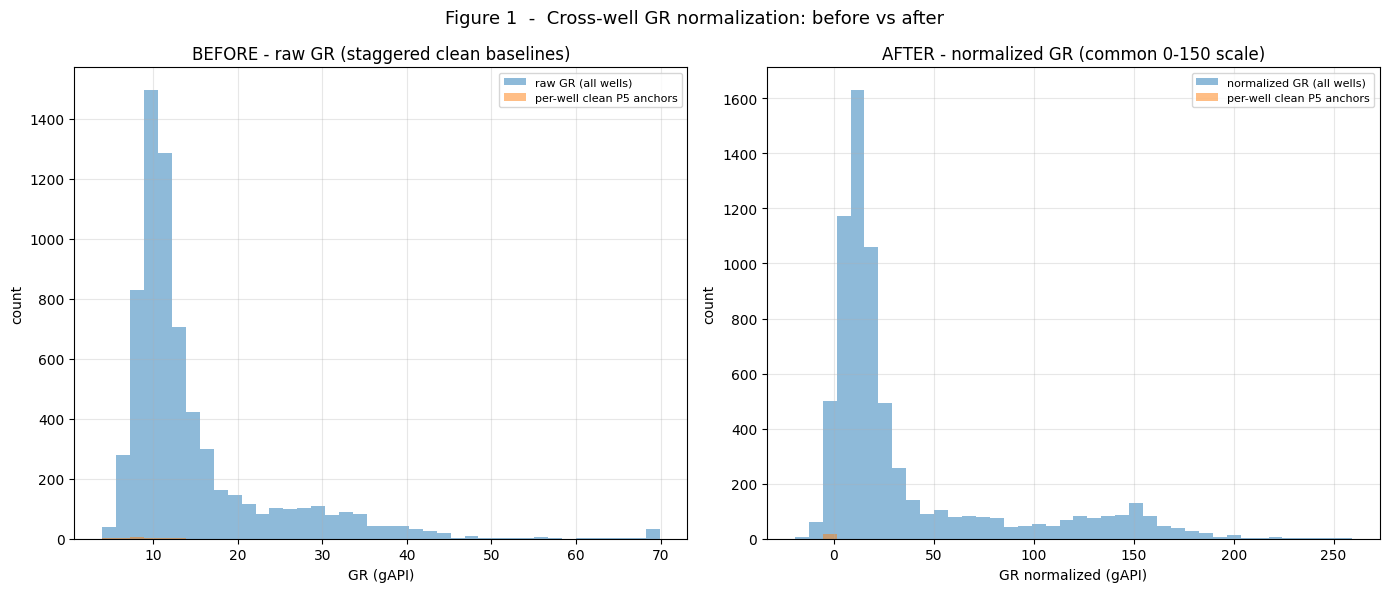

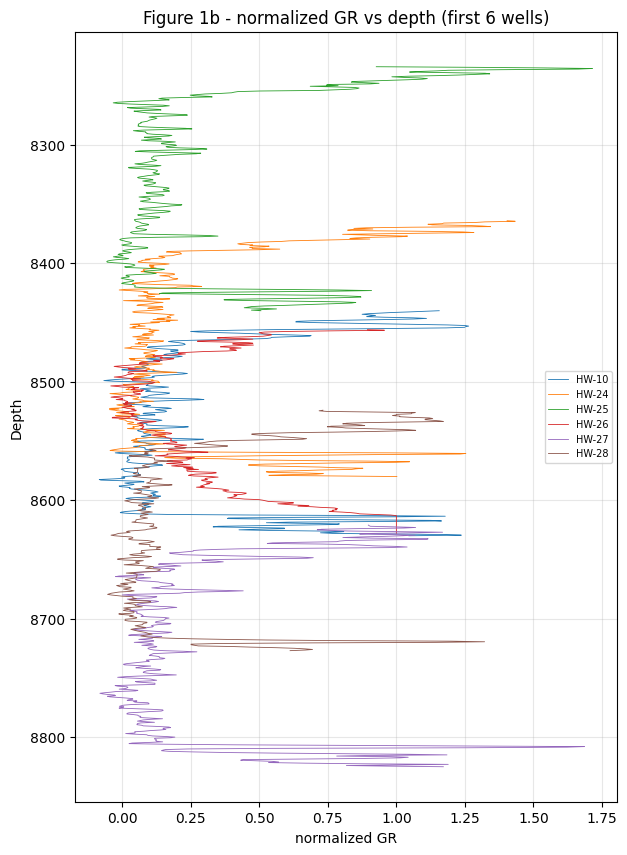

In [6]:
from petrophys.visualization import create_histogram_comparison, create_multiwell_overlay

# Figure 1: cross-well GR distributions before vs after normalization, rendered by
# the library histogram-comparison helper. We pool every well's clean-carbonate GR
# reading (its P5 anchor) so the panels show how the field-wide clean baseline
# collapses onto a single value after normalization.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# (a) raw GR pooled across all wells vs the per-well clean anchors
create_histogram_comparison(
    {'raw GR (all wells)': np.concatenate([gr_raw[wn] for wn in WELLS]),
     'per-well clean P5 anchors': clean_before},
    bins=40, ax=axes[0], xlabel='GR (gAPI)',
    title='BEFORE - raw GR (staggered clean baselines)',
)

# (b) normalized GR pooled across all wells vs the per-well clean anchors (aligned)
create_histogram_comparison(
    {'normalized GR (all wells)': np.concatenate([gr_norm[wn] for wn in WELLS]),
     'per-well clean P5 anchors': clean_after},
    bins=40, ax=axes[1], xlabel='GR normalized (gAPI)',
    title='AFTER - normalized GR (common 0-150 scale)',
)

fig.suptitle('Figure 1  -  Cross-well GR normalization: before vs after', fontsize=13)
plt.tight_layout()
plt.show()

# Companion view: GR vs depth overlaid for a handful of wells via the library
# multi-well overlay (normalize=True robustly min-max scales each well's curve),
# confirming the profiles line up on a common scale after normalization.
overlay_wells = [read_las(petrophys.sample(wn)) for wn in WELLS[:6]]
create_multiwell_overlay(overlay_wells, 'GR', normalize=True,
                         title='Figure 1b - normalized GR vs depth (first 6 wells)')
plt.show()

## 5. Integrated result - the field screening table

We assemble the per-well metrics into a single table and **sort by HCPT** (hydrocarbon pore
thickness) - the movable-hydrocarbon ranking key from Part 3.


In [7]:
screen = pd.DataFrame(ok)
screen = screen[['well', 'gross_ft', 'net_res_ft', 'net_pay_ft',
                 'avg_PHIE', 'avg_Sw', 'HCPT_ft', 'm_used', 'n_used', 'flags']]
screen = screen.sort_values('HCPT_ft', ascending=False).reset_index(drop=True)
screen.insert(0, 'rank', np.arange(1, len(screen) + 1))

print('=== COSTA FIELD SCREENING TABLE (17 wells, ranked by HCPT) ===')
print(screen.to_string(index=False))

print()
print('Field totals / stats:')
print('  Total net pay (all wells) : %.0f ft' % screen['net_pay_ft'].sum())
print('  Total HCPT (all wells)    : %.0f ft' % screen['HCPT_ft'].sum())
print('  Wells with net pay > 0    : %d / %d'
      % ((screen['net_pay_ft'] > 0).sum(), len(screen)))
print('  Wells on default m/n      : %d (Sw less certain)'
      % (screen['flags'] != '-').sum())

=== COSTA FIELD SCREENING TABLE (17 wells, ranked by HCPT) ===
 rank  well  gross_ft  net_res_ft  net_pay_ft  avg_PHIE  avg_Sw  HCPT_ft  m_used  n_used       flags
    1 HW-30     240.5       203.5       202.0     0.310   0.143    54.12    2.02    2.00           -
    2 HW-29     222.5       182.0       182.0     0.284   0.095    47.01    1.94    1.96           -
    3 HW-25     206.5       157.5       156.0     0.251   0.106    35.44    1.97    1.98           -
    4  HW-3     215.5       173.0       168.5     0.196   0.165    28.37    2.03    2.00           -
    5 HW-24     216.5       167.0       147.0     0.240   0.262    26.01    1.97    1.99           -
    6  HW-6     208.5       142.0       137.0     0.243   0.258    24.84    1.98    2.01           -
    7 HW-32     209.5       170.0       101.0     0.297   0.313    20.79    1.96    1.99           -
    8 HW-26     172.5        49.0        37.0     0.152   0.437     3.14    2.01    2.00           -
    9 HW-10     190.5       

**Figure 2 - ranked bar chart: net pay and HCPT per well.** Wells sorted by HCPT.
Net pay (ft) and HCPT (ft) are plotted side by side so we can see where thick pay does *not*
translate into hydrocarbon volume (tight or high-Sw pay).

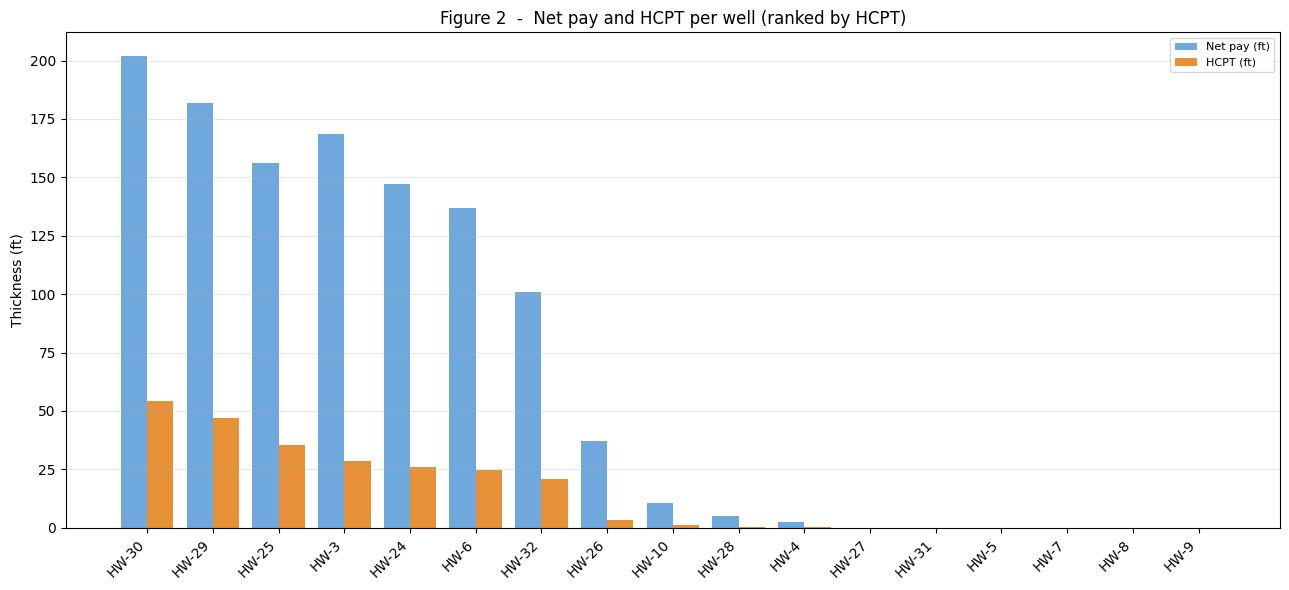

In [8]:
from petrophys.visualization import create_bar_comparison

# Figure 2: net pay and HCPT per well as grouped bars via the library bar helper.
# The table is already sorted by HCPT, so we plot in that order (no re-sort).
order = screen['well'].tolist()
fig, ax = create_bar_comparison(
    order,
    {'Net pay (ft)': screen['net_pay_ft'].values,
     'HCPT (ft)':    screen['HCPT_ft'].values},
    colors=['#6fa8dc', '#e69138'],
    figsize=(13, 6),
    ylabel='Thickness (ft)',
    title='Figure 2  -  Net pay and HCPT per well (ranked by HCPT)',
)
plt.tight_layout()
plt.show()

**Figure 3 - reservoir-quality scatter: average porosity vs average Sw over the pay,
coloured by HCPT (viridis colourbar).** With PHIE on the x-axis and Sw on the y-axis, the
best wells plot toward the **lower-right** - high porosity, low Sw - and that is exactly
where HW-30, HW-29 and HW-25 sit, in the brightest HCPT colours. Only pay-bearing wells
appear: wells with no pay have no pay-averaged PHIE/Sw and are dropped from this plot.

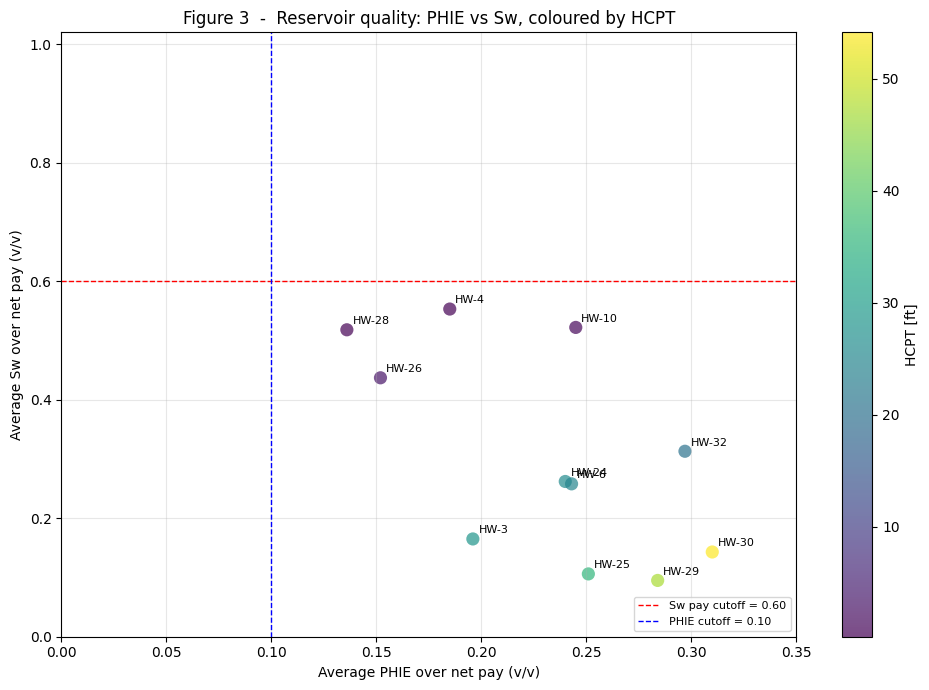

In [9]:
from petrophys.model.well import Well
from petrophys.visualization import create_crossplot

# Figure 3: reservoir-quality crossplot - average porosity vs average Sw over the
# pay, coloured by HCPT. The per-well screening aggregates are attached to a small
# aggregate "field" Well (real per-well averages) (one sample per pay-bearing well) so the library crossplot
# can render them, colour-coded by HCPT.
sub = screen.dropna(subset=['avg_PHIE', 'avg_Sw']).copy()

field = Well('Costa field screening')
field.depth = np.arange(len(sub), dtype=float)
field.add_curve('AVG_PHIE', sub['avg_PHIE'].values, unit='v/v')
field.add_curve('AVG_SW',   sub['avg_Sw'].values,   unit='v/v')
field.add_curve('HCPT',     sub['HCPT_ft'].values,  unit='ft')

cp = create_crossplot(
    field, 'AVG_PHIE', 'AVG_SW', color_curve='HCPT',
    xlim=(0, 0.35), ylim=(0, 1.02), cmap='viridis', marker_size=90,
    figsize=(10, 7),
    title='Figure 3  -  Reservoir quality: PHIE vs Sw, coloured by HCPT',
)
# annotate each well and add the cutoff reference lines on the returned axis
for _, r in sub.iterrows():
    cp.ax.annotate(r['well'], (r['avg_PHIE'], r['avg_Sw']),
                   xytext=(4, 4), textcoords='offset points', fontsize=8)
cp.ax.axhline(SW_CUT, color='r', ls='--', lw=1, label='Sw pay cutoff = %.2f' % SW_CUT)
cp.ax.axvline(PHIE_CUT, color='b', ls='--', lw=1, label='PHIE cutoff = %.2f' % PHIE_CUT)
cp.ax.set_xlabel('Average PHIE over net pay (v/v)')
cp.ax.set_ylabel('Average Sw over net pay (v/v)')
cp.ax.legend(loc='lower right', fontsize=8)
cp.show()

**Figure 4 - the two top-ranked wells, side by side.** A quick visual sanity check on
the winners: GR, porosity (PHIE), Sw and the net-pay flag for the #1 and #2 wells. Good
candidates show clean GR, high porosity and a thick low-Sw (gold) pay column.

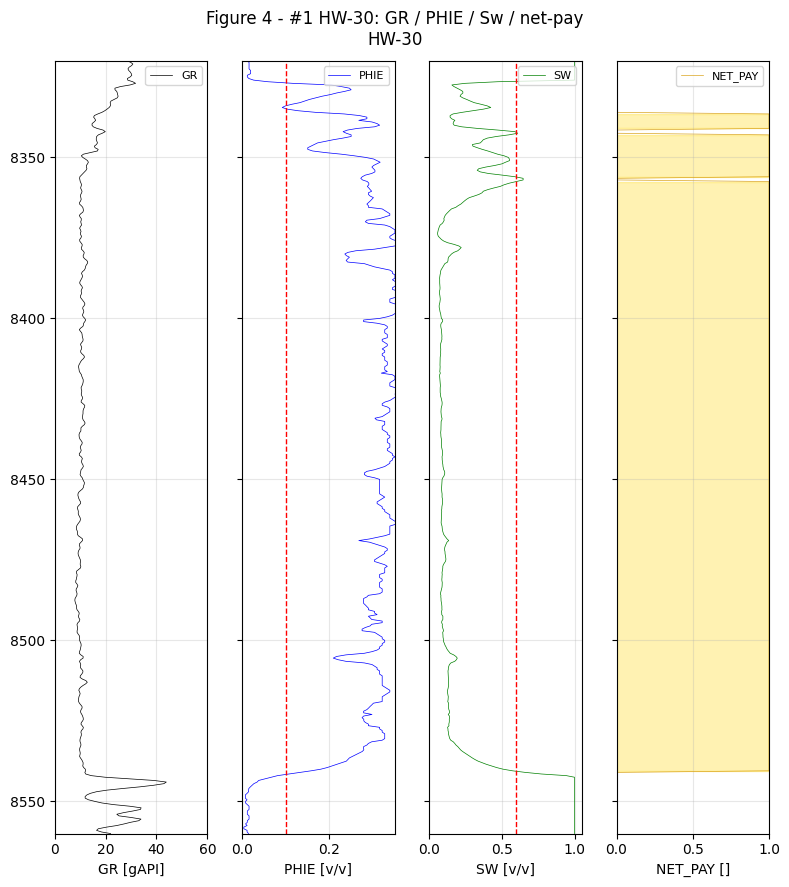

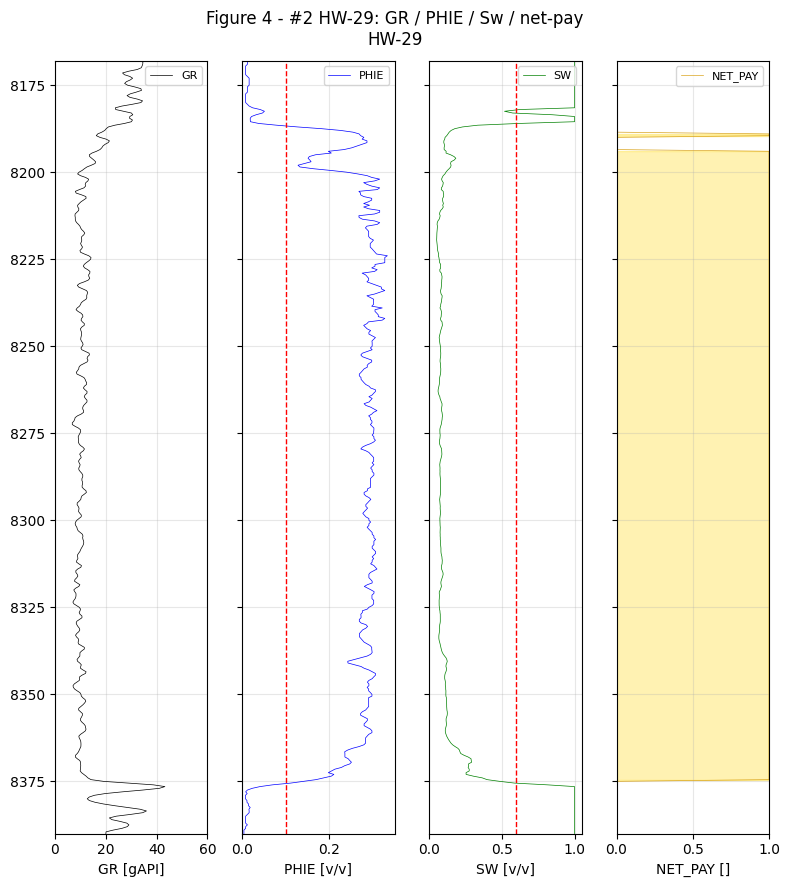

In [10]:
from petrophys.visualization import LogPlot


def quick_panel(well_name, title):
    """Compute the screening curves for one well, attach them, and render a
    4-track GR / PHIE / Sw / net-pay panel with the library LogPlot."""
    w = read_las(petrophys.sample(well_name))
    rw_ = w.get_parameter('RW'); rwt_ = w.get_parameter('RWT')
    a_ = w.get_parameter('A')
    m_ = w.get_parameter('M') or DEFAULT_M
    n_ = w.get_parameter('N') or DEFAULT_N
    bht_ = w.get_parameter('BHT')
    rhob = w.get('RHOB').data; nphi = w.get('NPHI').data
    phi = np.clip(poro.total_porosity(nphi, poro.density_porosity(rhob, RHOB_MATRIX, RHOB_FLUID),
                                      method='adaptive'), 0, 0.45)
    tf = calculate_temperature_profile(w, bht=bht_, surface_temp=rwt_).temperature
    sw = np.clip(sat.archie(w.get('RT').data, arps_equation(rw_, rwt_, tf), phi,
                            a=a_, m=m_, n=n_), 0, 1)
    gr = w.get('GR').data
    vcl = np.clip((gr - VCL_CLEAN) / (VCL_CLAY - VCL_CLEAN), 0, 1)
    w.add_curve('VCL', vcl); w.add_curve('PHIE', phi, unit='v/v'); w.add_curve('SW', sw, unit='v/v')
    npr = res_mod.calculate_net_pay(w, vcl_cutoff=VCL_CUT, phie_cutoff=PHIE_CUT,
                                    sw_cutoff=SW_CUT, lithology='carbonate')
    w.add_curve('NET_PAY', np.asarray(npr.net_pay, dtype=float), unit='')

    lp = LogPlot(w, figsize=(8, 9))
    lp.create_figure(n_tracks=4)
    lp.add_curve(0, 'GR', color='black', xlim=(0, 60))
    lp.add_curve(1, 'PHIE', color='blue', xlim=(0, 0.35))
    lp.axes[1].axvline(PHIE_CUT, color='r', ls='--', lw=1)
    lp.add_curve(2, 'SW', color='green', xlim=(0, 1.05))
    lp.axes[2].axvline(SW_CUT, color='r', ls='--', lw=1)
    lp.add_curve(3, 'NET_PAY', color='goldenrod', xlim=(0, 1))
    lp.add_fill(3, 'NET_PAY', 0.0, color='gold', where='right')
    lp.set_depth_range()
    lp.add_title(title)
    lp.show()


# Figure 4: quick QC panels for the two top-ranked wells.
top2 = screen['well'].iloc[:2].tolist()
quick_panel(top2[0], 'Figure 4 - #1 %s: GR / PHIE / Sw / net-pay' % top2[0])
quick_panel(top2[1], 'Figure 4 - #2 %s: GR / PHIE / Sw / net-pay' % top2[1])

## 6. Interpretation & deliverable

### The ranking

The field splits cleanly into three tiers on HCPT:

- **Tier 1 - development candidates (high HCPT):** the top wells combine thick net pay,
  high porosity (PHIE ~0.20-0.31) and low-to-moderate Sw (~0.10-0.31). These are the sweet
  spots.
- **Tier 2 - contingent / step-out:** moderate HCPT - real pay but either thinner,
  lower-porosity, or higher-Sw. Worth appraising, not the first dollar.
- **Tier 3 - wet (HCPT ~ 0):** wells that all carry substantial net reservoir - their
  porosity clears the cutoff - but whose Archie Sw is ~0.95-1.0 over the interval
  (genuinely water-bearing). HW-28 and HW-4 technically book 5.0 and 2.5 ft of pay - small
  but nonzero. Not development targets on today's data.


In [11]:
top3 = screen.head(3)
print('=== TOP 3 CANDIDATES FOR DEVELOPMENT ===')
print(top3[['rank', 'well', 'net_pay_ft', 'avg_PHIE', 'avg_Sw', 'HCPT_ft', 'flags']]
      .to_string(index=False))
print()
share = 100.0 * top3['HCPT_ft'].sum() / screen['HCPT_ft'].sum()
print('These 3 wells carry %.0f%% of the total field HCPT.' % share)
print()
print('Tier breakdown (by HCPT):')
t1 = screen[screen['HCPT_ft'] >= 20]
t2 = screen[(screen['HCPT_ft'] < 20) & (screen['HCPT_ft'] >= 1)]
t3 = screen[screen['HCPT_ft'] < 1]
print('  Tier 1 (HCPT >= 20 ft): %2d wells -> %s'
      % (len(t1), ', '.join(t1['well'])))
print('  Tier 2 (1-20 ft)      : %2d wells -> %s'
      % (len(t2), ', '.join(t2['well'])))
print('  Tier 3 (< 1 ft, wet)  : %2d wells -> %s'
      % (len(t3), ', '.join(t3['well'])))

=== TOP 3 CANDIDATES FOR DEVELOPMENT ===
 rank  well  net_pay_ft  avg_PHIE  avg_Sw  HCPT_ft flags
    1 HW-30       202.0     0.310   0.143    54.12     -
    2 HW-29       182.0     0.284   0.095    47.01     -
    3 HW-25       156.0     0.251   0.106    35.44     -

These 3 wells carry 57% of the total field HCPT.

Tier breakdown (by HCPT):
  Tier 1 (HCPT >= 20 ft):  7 wells -> HW-30, HW-29, HW-25, HW-3, HW-24, HW-6, HW-32
  Tier 2 (1-20 ft)      :  2 wells -> HW-26, HW-10
  Tier 3 (< 1 ft, wet)  :  8 wells -> HW-28, HW-4, HW-27, HW-31, HW-5, HW-7, HW-8, HW-9


### Recommendation (the deliverable)

**Prioritise the Tier-1 wells for development.** They dominate the field's hydrocarbon pore
volume, and their quality is driven by genuine rock properties (high porosity) *and*
charge (low Sw), not by a single favourable input. Concretely:

1. **Rank #1-#3** are the primary development candidates - carry the majority of field HCPT
   between them. Advance to volumetric/reserves work: multiply each well's HCPT by its
   drainage area and a recovery/FVF factor to get booked volumes.
2. **Tier 2** wells are appraisal / infill candidates: real pay, lower priority. Re-rank
   them once dynamic (pressure/production) data narrows the Sw uncertainty.
3. **Tier 3** wells are wet on this interpretation. Before writing them off, confirm the FWL
   and check whether a *different* zone (outside the screened interval) is charged - but they
   are not first-phase targets.
4. **Discount any candidate flagged `M=def`/`N=def`.** Their Sw rests on assumed exponents;
   acquire or model m/n before booking volumes on them.

A note on the GR normalization (Part 4b): the ranking loop itself uses each well's **raw** GR
with fixed 8/40 gAPI Vcl anchors - the normalized GR is never fed into any ranked quantity.
Normalization ran alongside the screen as a QC check, and it shows the per-well clean anchors
spread only 5.1-13.6 gAPI, so the fixed anchors are tolerable field-wide. A production
screening should close the loop and feed `gr_norm` into the Vcl step.


## 7. Limitations & assumptions

Screening is deliberately fast and uniform, which means honest caveats:

- **Volumetric, not economic.** HCPT is a *per-well column* index (ft). It is **not** OOIP:
  it omits drainage area, formation-volume factor, and recovery efficiency. It ranks wells;
  it does not book barrels.
- **One recipe for 17 wells.** We applied a single carbonate matrix (calcite, 2.71 g/cc),
  one N-D porosity method, and one cutoff set to every well. Individual wells may warrant
  local matrix or cutoff tuning; that would change absolute numbers, but rarely the ranking.
- **Assumed Archie exponents on some wells.** Wells flagged `M=def`/`N=def` use carbonate
  defaults `m = n = 2.0`. Their Sw - and therefore their HCPT - carries extra uncertainty.
- **Rw temperature correction depends on BHT.** We trust the header `BHT` and a
  surface-to-BHT gradient. A wrong BHT tilts Sw the same way on every well (a systematic, not
  random, error).
- **No independent FWL per well.** We screen on log Sw against fixed cutoffs; we did not fit a
  saturation-height / free-water-level model per well (that was CS2's job on a single well).
  Tier-3 "wet" calls should be confirmed against pressure/FWL data.
- **No borehole-quality mask.** Costa wells have no caliper, so we could not exclude washed-out
  intervals; badly enlarged hole would inflate porosity and pay locally.


## 8. Appendix - reproduce & extend

**Re-run the whole screen** on any subset of Costa wells - the `screen_well` recipe is
self-contained:

```python
subset = ['HW-30', 'HW-29', 'HW-25']
df = pd.DataFrame([screen_well(wn) for wn in subset])
df.sort_values('HCPT_ft', ascending=False)
```

**Apply to a new field:** point `screen_well` at a different sample set from
`petrophys.list_samples(...)`. For clastics, change `lithology='clastic'` in
`calculate_net_pay`, set `RHOB_MATRIX = 2.65` (quartz), and use clastic GR anchors.

**Tighten the screen:** to convert HCPT into real volumes, multiply each well's `HCPT_ft` by
its drainage area (`acres * 43560` ft^2) and divide by the oil FVF - the summation module
(`petrophys.evaluation.summaries.calculate_hcpv` / `calculate_ooip`) does this properly once you have
areas.

The cell below re-emits the final ranked screening table as the portfolio deliverable.


In [12]:
print('COSTA FIELD - FINAL SCREENING DELIVERABLE (ranked by HCPT)')
print('=' * 78)
print(screen.to_string(index=False))
print()
print('Top-3 development candidates:', ', '.join(screen['well'].head(3)))

COSTA FIELD - FINAL SCREENING DELIVERABLE (ranked by HCPT)
 rank  well  gross_ft  net_res_ft  net_pay_ft  avg_PHIE  avg_Sw  HCPT_ft  m_used  n_used       flags
    1 HW-30     240.5       203.5       202.0     0.310   0.143    54.12    2.02    2.00           -
    2 HW-29     222.5       182.0       182.0     0.284   0.095    47.01    1.94    1.96           -
    3 HW-25     206.5       157.5       156.0     0.251   0.106    35.44    1.97    1.98           -
    4  HW-3     215.5       173.0       168.5     0.196   0.165    28.37    2.03    2.00           -
    5 HW-24     216.5       167.0       147.0     0.240   0.262    26.01    1.97    1.99           -
    6  HW-6     208.5       142.0       137.0     0.243   0.258    24.84    1.98    2.01           -
    7 HW-32     209.5       170.0       101.0     0.297   0.313    20.79    1.96    1.99           -
    8 HW-26     172.5        49.0        37.0     0.152   0.437     3.14    2.01    2.00           -
    9 HW-10     190.5       149.

### Recap

- We turned a single-well carbonate recipe (CS2) into a **17-well batch screen** with one
  uniform, verified workflow and graceful handling of missing curves/parameters.
- The **Rw -> formation-temperature** Arps correction is the dominant correctness step; skip
  it and Sw sits at or above 1 almost everywhere on every well.
- **GR normalization** ran alongside the ranking as a QC check: the per-well clean anchors
  spread only 5.1-13.6 gAPI, so the fixed 8/40 gAPI Vcl anchors are tolerable field-wide.
  The ranking itself uses raw GR; a production screen should feed `gr_norm` into the Vcl
  step.
- We ranked the field on **hydrocarbon pore thickness (HCPT)** and delivered a tiered
  **top-candidates** list with rationale and honest limitations.

**Next:** CS4 - making a defensible interpretation from an *imperfect* well (missing curves,
off-scale resistivity, ML imputation).


**Cross-check against lesson 18.** The multi-well field study (lesson 18) batch-runs
this same field through the dynamic workflow at the same Costa project cutoff set. Its per-well
net pay differs from this screening by up to ~10% (e.g. HW-30: 202.5 ft here vs 185.0 ft
there). The cutoffs are identical - the residual is the *recipe*: this screening uses the
header Archie constants with an Arps-corrected Rw and a density-neutron porosity, while
the batch workflow uses its own porosity and Sw chain. Two defensible recipes, one
documented difference.